# Clasificación de solicitudes de ciberseguridad defensiva mediante fine-tuning de BERT

**Asignatura:** Procesamiento de Lenguaje Natural / Inteligencia Artificial  
**Dataset:** [`Reizxn/HolyCyber`](https://huggingface.co/datasets/Reizxn/HolyCyber)  
**Modelo base:** `bert-base-uncased`  
**Técnica:** fine-tuning supervisado con Hugging Face `Trainer`  
**Tipo de problema:** clasificación multiclase de texto (17 dominios)

## Objetivo general

Construir y evaluar un modelo de clasificación de texto basado en BERT que, a partir de la pregunta o solicitud escrita por un usuario, prediga el dominio de ciberseguridad defensiva al que pertenece según la etiqueta `domain` del dataset HolyCyber.

El proyecto sigue el flujo del material de referencia *Fine-tuning a model with the Trainer API or Keras*: cargar datos, tokenizar, crear un modelo de clasificación, entrenar con `Trainer`, predecir y calcular métricas. Se amplía con análisis exploratorio, uso de las particiones oficiales, control de fuga entre particiones, experimentación de hiperparámetros, baseline TF-IDF, análisis de errores y guardado del mejor modelo.

> **Alcance:** este notebook resuelve una tarea de clasificación de solicitudes. No genera consejos de ciberseguridad ni ejecuta acciones de seguridad. El dataset se describe como defensivo y el modelo solo predice una de sus etiquetas temáticas.

## 1. Descripción del problema y del dominio

### Dominio

El proyecto pertenece al Procesamiento de Lenguaje Natural (NLP) aplicado a la ciberseguridad defensiva. Las solicitudes de seguridad informática pueden tratar sobre inteligencia de amenazas, gestión de vulnerabilidades, ingeniería de detección, respuesta a incidentes, seguridad de redes, seguridad en la nube, programación segura, entre otros temas.

### Problema que se busca resolver

Una organización puede recibir consultas de seguridad informática muy variadas. Clasificarlas automáticamente por dominio permite organizar solicitudes, dirigirlas al equipo especializado correspondiente y facilitar la búsqueda de conocimiento técnico.

El modelo recibirá únicamente el contenido del mensaje del usuario y predecirá una de las 17 categorías `domain` definidas por HolyCyber. No se utilizará la respuesta del asistente, el nombre del dominio, el subdominio ni otros metadatos como entrada; de esta forma evitamos entregar al modelo la etiqueta que debe aprender.

### Dataset y procedencia

HolyCyber es un conjunto de instrucciones de ciberseguridad defensiva en inglés. Su versión 2.3.0 declara 51.805 registros, distribuidos en `train` (40.998), `validation` (5.105) y `test` (5.702). Cada registro contiene una conversación de tres mensajes (`system`, `user`, `assistant`) y metadatos como dominio, subdominio, tipo de tarea, dificultad, fuente y licencia.

La tarjeta del dataset indica que las particiones se construyeron por `group_key` para evitar que una misma entidad de origen aparezca en más de una partición. También advierte que parte de las respuestas incluye apéndices de referencia reutilizados y que el conjunto no fue revisado fila por fila por especialistas. Por ello, en este proyecto se utiliza solamente el mensaje `user` como texto de entrada y se comprueba la separación de grupos.

**Fuente:** [Reizxn/HolyCyber – tarjeta y archivos del dataset](https://huggingface.co/datasets/Reizxn/HolyCyber). La cantidad real se vuelve a comprobar al descargar los archivos, ya que el repositorio puede actualizarse.

### Variables principales

| Variable | Descripción | Uso |
|---|---|---|
| `messages` | Conversación de tres turnos (`system`, `user`, `assistant`). | Se extrae solo el mensaje con `role=user` como entrada. |
| `domain` | Dominio temático asignado al registro. | Variable objetivo (Y), 17 clases. |
| `subdomain` | Subárea dentro del dominio. | Descriptivo para el EDA; no se entrega al modelo. |
| `task_type` | Forma o tipo de tarea solicitada. | Descriptivo para el EDA; no se entrega al modelo. |
| `difficulty` | Nivel de dificultad derivado del tipo de tarea. | Descriptivo para el EDA; no se entrega al modelo. |
| `group_key` | Entidad de origen usada para construir las particiones. | Auditoría de fuga entre particiones; no se entrega al modelo. |
| `source` | Fuente documental del registro. | Trazabilidad y EDA; no se entrega al modelo. |
| `license` | Licencia asociada a la fuente del registro. | Trazabilidad; no se entrega al modelo. |
| `tokens`, `core_share`, `appendix` | Metadatos de longitud y composición de la respuesta. | Análisis descriptivo; no se entrega al modelo. |

### Dominios incluidos

| Etiqueta (`domain`) | Interpretación en español |
|---|---|
| `threat_intelligence` | Inteligencia de amenazas |
| `attack_knowledge` | Conocimiento de patrones de ataque |
| `vulnerability_management` | Gestión de vulnerabilidades |
| `detection_engineering` | Ingeniería de detección |
| `defense_engineering` | Ingeniería de defensa |
| `ai_ml_security` | Seguridad de inteligencia artificial y aprendizaje automático |
| `secure_coding` | Programación segura |
| `pentest` | Pruebas de penetración autorizadas |
| `incident_response` | Respuesta a incidentes |
| `network_security` | Seguridad de redes |
| `cloud_security` | Seguridad en la nube |
| `malware_analysis` | Análisis de malware |
| `identity_access` | Identidad y control de acceso |
| `cryptography` | Criptografía |
| `governance_risk` | Gobierno, riesgo y cumplimiento |
| `ml_security_methodology` | Metodología de seguridad para ML |
| `safety_boundary` | Límites de seguridad, evaluación y red teaming |

### Formulación del aprendizaje

- **Entrada (X):** contenido textual del mensaje `user` dentro de `messages`.
- **Salida (Y):** columna `domain`, codificada como una de 17 clases.
- **Tipo de problema:** clasificación supervisada multiclase de texto.
- **Modelo:** `bert-base-uncased`, modelo BERT preentrenado en inglés.
- **Técnica:** fine-tuning; se ajustan los pesos de BERT y una cabeza de clasificación de 17 salidas.
- **Métrica principal:** F1-score macro, porque da el mismo peso a cada dominio. También se reportan accuracy, precision, recall y F1 ponderado.

### Decisiones metodológicas y limitaciones

1. Se utiliza únicamente el mensaje del usuario. No se utilizan `system` ni `assistant`, porque contienen instrucciones generales o respuestas que podrían revelar la categoría.
2. `domain` es la etiqueta original del dataset. El modelo aprende a reproducir esa clasificación; no se afirma que las categorías sean una taxonomía universal ni que todas las anotaciones sean infalibles.
3. Se respetan las particiones oficiales `train`, `validation` y `test`. No se mezclan ni se vuelven a dividir aleatoriamente, y se verifica que `group_key` no cruce particiones.
4. Se excluyen registros sin pregunta o sin etiqueta válida. Se detectan preguntas idénticas entre particiones y se informa su cantidad.
5. Los textos se truncan a un máximo de 256 tokens WordPiece para controlar memoria y tiempo de entrenamiento. El porcentaje se calcula con el tokenizador real de BERT.
6. El dataset declara licencia `mixed-per-source`: las fuentes originales no comparten una única licencia. Este notebook no redistribuye los JSONL. Antes de compartir registros o pesos del modelo, se deben revisar las condiciones por fuente y la atribución requerida.
7. La tarjeta advierte que las respuestas contienen referencias reutilizadas en una parte de los registros. Por eso no se utiliza el texto de respuesta como entrada y se documenta esta limitación.

## 2. Instalación e importación de librerías

Se utiliza una combinación de versiones compatible con el entorno de Google Colab empleado en el proyecto anterior. PyTorch no se reinstala para conservar la compilación que proporciona Colab y su soporte de GPU. La API utilizada corresponde a `eval_strategy` en `TrainingArguments` y `processing_class` en `Trainer`.

In [27]:
%pip install -q --upgrade \
    "transformers==5.22.1" \
    "datasets==4.8.5" \
    "accelerate==1.15.0" \
    "huggingface-hub==1.32.0" \
    "fsspec==2025.12.0" \
    "pandas==2.2.3" \
    "pyarrow==23.0.1" \
    scikit-learn matplotlib seaborn

### Explicación del bloque: instalación de dependencias
Esta celda instala las bibliotecas necesarias para ejecutar el proyecto. `transformers` proporciona BERT y las herramientas de entrenamiento; `datasets` permite cargar y transformar el dataset; `accelerate` facilita el uso del hardware; `pandas` organiza los datos en tablas; y `scikit-learn`, `matplotlib` y `seaborn` permiten calcular métricas y visualizar resultados. Se fijan versiones para hacer el entorno más reproducible. PyTorch no se reinstala para conservar la versión y el soporte de GPU que ofrece Colab.

In [2]:
import os
import shutil
import re
import json
import random
import warnings
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import transformers
import datasets

from IPython.display import display
from huggingface_hub import hf_hub_download
from datasets import load_dataset, Dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    DataCollatorWithPadding,
    TrainingArguments,
    Trainer,
    set_seed,
)
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
    f1_score,
)
from sklearn.utils.class_weight import compute_class_weight

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

SEED = 42
set_seed(SEED)
random.seed(SEED)
np.random.seed(SEED)

print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
if transformers.__version__ != "4.57.6":
    raise RuntimeError(
        "Versión de Transformers incorrecta. Reinicia el entorno después de instalar las dependencias "
        "y vuelve a ejecutar el notebook desde el principio. Versión esperada: 4.57.6."
    )
print("Datasets:", datasets.__version__)
print("Pandas:", pd.__version__)
print("GPU disponible:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Aviso: no se detectó GPU. El entrenamiento puede tardar bastante más.")

PyTorch: 2.11.0+cu130
Transformers: 4.57.6
Datasets: 4.8.5
Pandas: 2.2.3
GPU disponible: True
GPU: Tesla T4


### Explicación del bloque: importaciones y reproducibilidad
Aquí se importan las herramientas que se utilizarán durante todo el notebook. Se incluyen librerías para manipulación de datos, gráficos, entrenamiento de modelos y evaluación. La variable `SEED = 42` fija una semilla para que operaciones aleatorias —como la selección de muestras y la inicialización— sean más reproducibles. Finalmente, se consulta si hay GPU disponible: el entrenamiento puede ejecutarse sin ella, pero tardará más.

## 3. Descarga y carga del dataset HolyCyber

La tarjeta publica tres archivos JSONL globales: `dataset/train.jsonl`, `dataset/val.jsonl` y `dataset/test.jsonl`. Se descargan con `hf_hub_download` y se cargan como particiones separadas. La descarga puede ser grande; se recomienda ejecutar el notebook en Colab con almacenamiento y GPU disponibles.

In [3]:
DATASET_ID = "Reizxn/HolyCyber"
DATASET_REVISION = "main"  # Se registra la revisión usada; el repositorio puede actualizarse.
ARCHIVOS_DATASET = {
    "train": "train.jsonl",
    "validation": "val.jsonl",
    "test": "test.jsonl",
}
rutas_locales = {}
for split, filename in ARCHIVOS_DATASET.items():
    print(f"Descargando {filename} ...")
    rutas_locales[split] = hf_hub_download(
        repo_id=DATASET_ID,
        filename=filename,
        repo_type="dataset",
        revision=DATASET_REVISION,
    )

raw_datasets = load_dataset("json", data_files=rutas_locales)
print(raw_datasets)
for split in raw_datasets:
    print(f"{split}: {len(raw_datasets[split]):,} registros")

Descargando train.jsonl ...


train.jsonl:   0%|          | 0.00/527M [00:00<?, ?B/s]

Descargando val.jsonl ...


val.jsonl:   0%|          | 0.00/65.6M [00:00<?, ?B/s]

Descargando test.jsonl ...


test.jsonl:   0%|          | 0.00/73.1M [00:00<?, ?B/s]

Generating train split: 0 examples [00:00, ? examples/s]

Generating validation split: 0 examples [00:00, ? examples/s]

Generating test split: 0 examples [00:00, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['id', 'row_key', 'domain', 'subdomain', 'task_type', 'difficulty', 'group_key', 'source', 'license', 'split', 'canary', 'tokens', 'core_share', 'appendix', 'references', 'messages'],
        num_rows: 40998
    })
    validation: Dataset({
        features: ['id', 'row_key', 'domain', 'subdomain', 'task_type', 'difficulty', 'group_key', 'source', 'license', 'split', 'canary', 'tokens', 'core_share', 'appendix', 'references', 'messages'],
        num_rows: 5105
    })
    test: Dataset({
        features: ['id', 'row_key', 'domain', 'subdomain', 'task_type', 'difficulty', 'group_key', 'source', 'license', 'split', 'canary', 'tokens', 'core_share', 'appendix', 'references', 'messages'],
        num_rows: 5702
    })
})
train: 40,998 registros
validation: 5,105 registros
test: 5,702 registros


### Explicación del bloque: descarga y carga de HolyCyber
Se define el repositorio de Hugging Face y los tres archivos de datos: entrenamiento, validación y prueba. `hf_hub_download` descarga cada archivo y devuelve su ruta local. Después, `load_dataset` interpreta los JSONL y los organiza en particiones independientes. Mantener estas particiones separadas permite entrenar con `train`, seleccionar configuraciones con `validation` y reservar `test` para la evaluación final.

## 4. Inspección de estructura y extracción del mensaje del usuario

Cada registro contiene una lista `messages` con roles `system`, `user` y `assistant`. La función siguiente identifica explícitamente el mensaje `user`; no supone que siempre ocupe una posición fija. Se conservan solo las columnas necesarias para el proyecto y la auditoría, y se descartan las respuestas largas del asistente para reducir el uso de memoria.

In [4]:
def extraer_mensaje_usuario(messages):
    """Devuelve el contenido del mensaje role=user, tolerando JSON serializado."""
    if isinstance(messages, str):
        try:
            messages = json.loads(messages)
        except json.JSONDecodeError:
            return ""
    if not isinstance(messages, (list, tuple)):
        return ""
    for mensaje in messages:
        if isinstance(mensaje, dict) and mensaje.get("role") == "user":
            return str(mensaje.get("content", "") or "").strip()
    return ""


def compactar_lote(batch):
    textos = [extraer_mensaje_usuario(x) for x in batch["messages"]]
    tokens = batch.get("tokens", [{} for _ in textos])
    tokens_usuario = [x.get("user") if isinstance(x, dict) else None for x in tokens]
    tokens_total = [x.get("total") if isinstance(x, dict) else None for x in tokens]
    return {
        "text": textos,
        "tokens_user_metadata": tokens_usuario,
        "tokens_total_metadata": tokens_total,
    }

columnas_originales = raw_datasets["train"].column_names
compact_datasets = {}
for split, dataset in raw_datasets.items():
    compact_datasets[split] = dataset.map(
        compactar_lote,
        batched=True,
        batch_size=128,
        remove_columns=columnas_originales,
        desc=f"Extrayendo preguntas de {split}",
    )

print("Columnas compactadas:", compact_datasets["train"].column_names)
print("Ejemplo de pregunta:")
print(compact_datasets["train"][0]["text"][:1200])

Extrayendo preguntas de train:   0%|          | 0/40998 [00:00<?, ? examples/s]

Extrayendo preguntas de validation:   0%|          | 0/5105 [00:00<?, ? examples/s]

Extrayendo preguntas de test:   0%|          | 0/5702 [00:00<?, ? examples/s]

Columnas compactadas: ['text', 'tokens_user_metadata', 'tokens_total_metadata']
Ejemplo de pregunta:
Summarise the ATT&CK campaign Frankenstein (C0001).

Cover all of the following in depth, and stay concrete:
- Overview
- Techniques observed
- First/last seen

Then add a reference appendix: related records from the same corpus that a practitioner would want beside this answer, clearly marked as reference material.


### Explicación del bloque: extracción del texto de entrada
`extraer_mensaje_usuario` recorre la conversación y localiza el elemento cuyo rol es `user`; así no depende de que el mensaje esté siempre en una posición fija. También contempla que `messages` llegue como texto JSON. `compactar_lote` aplica la extracción por lotes y conserva algunos metadatos de longitud, mientras elimina columnas originales que no son necesarias para el modelo. La decisión importante es que BERT recibe la solicitud del usuario, no la respuesta del asistente.

## 5. Preparación y control de calidad

Se convierten las particiones compactadas a DataFrames para el análisis. Se eliminan preguntas vacías y etiquetas no válidas. Se comprueba que las 17 clases estén presentes en entrenamiento y se audita el aislamiento de `group_key` entre las particiones oficiales.

In [5]:
def dataset_a_dataframe(dataset, split_name):
    columnas = {
        "text": dataset["text"],
        "tokens_user_metadata": dataset["tokens_user_metadata"],
        "tokens_total_metadata": dataset["tokens_total_metadata"],
    }
    # Metadatos originales necesarios para EDA y auditoría.
    for col in ["id", "domain", "subdomain", "task_type", "difficulty", "group_key", "source", "license", "core_share", "appendix"]:
        if col in raw_datasets[split_name].column_names:
            columnas[col] = raw_datasets[split_name][col]
    frame = pd.DataFrame(columnas)
    frame["split"] = split_name
    return frame

train_df = dataset_a_dataframe(compact_datasets["train"], "train")
val_df = dataset_a_dataframe(compact_datasets["validation"], "validation")
test_df = dataset_a_dataframe(compact_datasets["test"], "test")

filas_antes = {"train": len(train_df), "validation": len(val_df), "test": len(test_df)}
for frame in [train_df, val_df, test_df]:
    frame["text"] = frame["text"].fillna("").astype(str).str.strip()
    frame["domain"] = frame["domain"].fillna("").astype(str).str.strip()
    frame.drop(frame[(frame["text"] == "") | (frame["domain"] == "")].index, inplace=True)
    frame.reset_index(drop=True, inplace=True)

print("Registros por partición descargados:", filas_antes)
print("Registros válidos:", {"train": len(train_df), "validation": len(val_df), "test": len(test_df)})
print("Total válido:", len(train_df) + len(val_df) + len(test_df))
print("Columnas disponibles:", list(train_df.columns))
print("Nulos por columna en train:")
display(train_df.isna().sum().to_frame("faltantes"))

clases = sorted(train_df["domain"].unique().tolist())
clases_fuera = (set(val_df["domain"].unique()) | set(test_df["domain"].unique())) - set(clases)
if clases_fuera:
    raise ValueError(f"Hay clases no presentes en train: {clases_fuera}")
if len(clases) != 17:
    print(f"Advertencia: la partición train contiene {len(clases)} clases, no 17. Se usará el número real.")

print(f"Número de dominios en train: {len(clases)}")
print("Dominios:", clases)

Registros por partición descargados: {'train': 40998, 'validation': 5105, 'test': 5702}
Registros válidos: {'train': 40998, 'validation': 5105, 'test': 5702}
Total válido: 51805
Columnas disponibles: ['text', 'tokens_user_metadata', 'tokens_total_metadata', 'id', 'domain', 'subdomain', 'task_type', 'difficulty', 'group_key', 'source', 'license', 'core_share', 'appendix', 'split']
Nulos por columna en train:


,faltantes
text,0
tokens_user_metadata,0
tokens_total_metadata,0
id,0
domain,0
subdomain,0
task_type,0
difficulty,0
group_key,0
source,0


Número de dominios en train: 17
Dominios: ['ai_ml_security', 'attack_knowledge', 'cloud_security', 'cryptography', 'defense_engineering', 'detection_engineering', 'governance_risk', 'identity_access', 'incident_response', 'malware_analysis', 'ml_security_methodology', 'network_security', 'pentest', 'safety_boundary', 'secure_coding', 'threat_intelligence', 'vulnerability_management']


### Explicación del bloque: DataFrames y limpieza
La función `dataset_a_dataframe` combina el texto extraído con metadatos útiles para el análisis y la auditoría. Luego se crean `train_df`, `val_df` y `test_df`. Se limpian valores nulos, se convierten texto y etiqueta a cadenas y se eliminan registros sin pregunta o sin dominio. Finalmente se identifican las clases presentes en entrenamiento y se comprueba que validación y prueba no introduzcan categorías desconocidas.

In [6]:
# Auditoría de fuga por grupo: la tarjeta indica que el split se construyó por group_key.
def grupos(frame):
    if "group_key" not in frame.columns:
        return set()
    return set(frame["group_key"].dropna().astype(str))

sets_grupo = {"train": grupos(train_df), "validation": grupos(val_df), "test": grupos(test_df)}
for a, b in [("train", "validation"), ("train", "test"), ("validation", "test")]:
    interseccion = sets_grupo[a] & sets_grupo[b]
    print(f"group_key compartidos entre {a} y {b}: {len(interseccion)}")
    if interseccion:
        print("Muestra de grupos compartidos:", list(interseccion)[:5])

# Auditoría de preguntas normalizadas repetidas entre particiones.
def normalizar_texto(s):
    return re.sub(r"\\s+", " ", str(s).lower()).strip()

for frame in [train_df, val_df, test_df]:
    frame["text_norm"] = frame["text"].map(normalizar_texto)
sets_texto = {name: set(frame["text_norm"]) for name, frame in [("train", train_df), ("validation", val_df), ("test", test_df)]}
for a, b in [("train", "validation"), ("train", "test"), ("validation", "test")]:
    print(f"Preguntas idénticas entre {a} y {b}: {len(sets_texto[a] & sets_texto[b])}")

# El canary de la tarjeta es metadato de decontaminación, no una característica del modelo.
CANARY = "HOLYCYBER-DECONTAM-CANARY"
canary_en_texto = sum(frame["text"].str.contains(CANARY, case=False, na=False).sum() for frame in [train_df, val_df, test_df])
print("Marcador canary encontrado en mensajes de usuario:", canary_en_texto)

group_key compartidos entre train y validation: 0
group_key compartidos entre train y test: 0
group_key compartidos entre validation y test: 0
Preguntas idénticas entre train y validation: 0
Preguntas idénticas entre train y test: 0
Preguntas idénticas entre validation y test: 0
Marcador canary encontrado en mensajes de usuario: 0


### Explicación del bloque: auditoría contra fuga de información
Este bloque comprueba que las particiones no compartan `group_key`, que identifica grupos de origen. También normaliza las preguntas —minúsculas y espacios consistentes— para detectar textos repetidos entre entrenamiento, validación y prueba. Por último, busca el marcador de descontaminación indicado por la tarjeta del dataset. Estas comprobaciones ayudan a detectar solapamientos que podrían producir métricas artificialmente altas. Los metadatos de auditoría no se entregan como características al clasificador.

## 6. Análisis exploratorio de datos (EDA)

El EDA describe el número de registros, la distribución de los 17 dominios, los subdominios, los tipos de tarea, la dificultad y la longitud de las preguntas. Se utilizan solo columnas descriptivas: ni `domain` ni otros metadatos se concatenan al texto que recibirá BERT.

In [7]:
df_all = pd.concat([train_df, val_df, test_df], ignore_index=True)
print("Dimensiones globales después de limpieza:", df_all.shape)
print("Particiones:")
display(df_all["split"].value_counts().rename_axis("partición").to_frame("registros"))

conteo_dominios = df_all["domain"].value_counts().sort_values(ascending=False)
tabla_dominios = pd.DataFrame({
    "registros": conteo_dominios,
    "porcentaje": (conteo_dominios / len(df_all) * 100).round(2),
}).rename_axis("domain")
display(tabla_dominios)

print("Estadísticas de distribución por dominio:")
print("Dominio con más registros:", conteo_dominios.idxmax(), int(conteo_dominios.max()))
print("Dominio con menos registros:", conteo_dominios.idxmin(), int(conteo_dominios.min()))
print("Razón máximo/mínimo:", round(conteo_dominios.max() / conteo_dominios.min(), 2))

Dimensiones globales después de limpieza: (51805, 15)
Particiones:


,registros
partición,
train,40998
test,5702
validation,5105


,registros,porcentaje
domain,,
detection_engineering,7970,15.38
ai_ml_security,4602,8.88
vulnerability_management,3493,6.74
governance_risk,3176,6.13
defense_engineering,2986,5.76
incident_response,2943,5.68
attack_knowledge,2887,5.57
threat_intelligence,2865,5.53
pentest,2788,5.38


Estadísticas de distribución por dominio:
Dominio con más registros: detection_engineering 7970
Dominio con menos registros: cryptography 2100
Razón máximo/mínimo: 3.8


### Explicación del bloque: resumen cuantitativo del EDA
Se unen temporalmente las tres particiones para describir el conjunto completo, sin cambiar su separación original. La celda calcula el tamaño total, el número de registros por partición y la frecuencia y porcentaje de cada dominio. También identifica el dominio más y menos frecuente y calcula la relación entre ambos volúmenes. Esto permite reconocer posibles desbalances antes de entrenar.

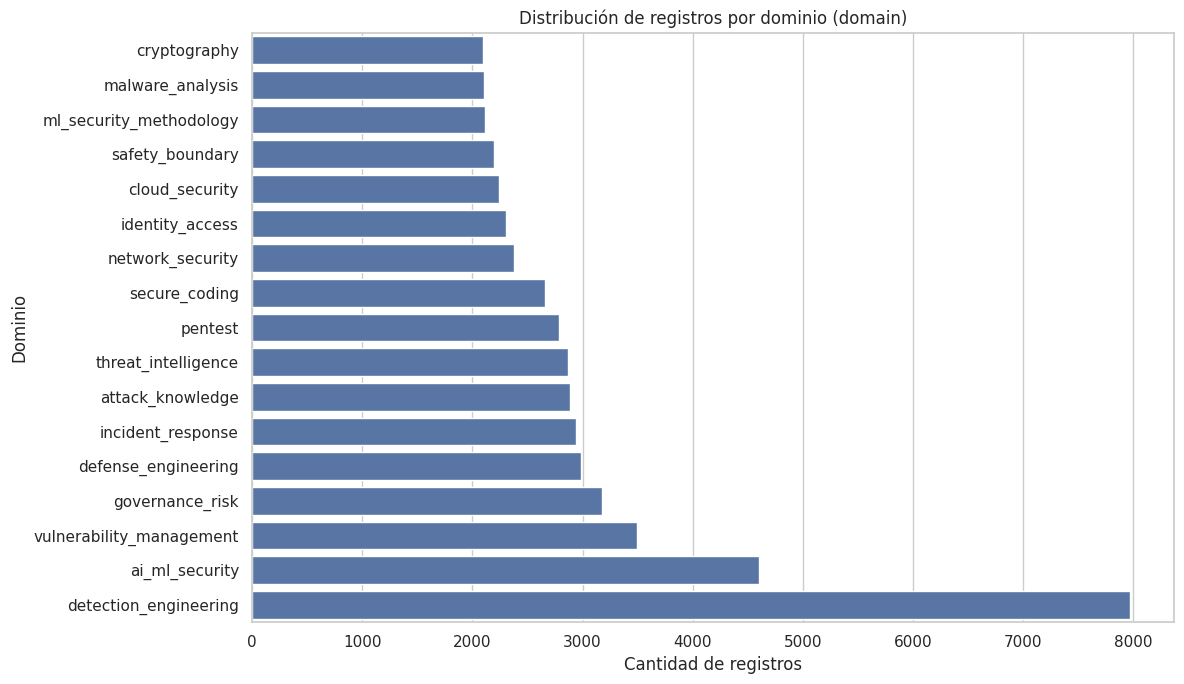

Conteos por dominio y partición:


split,test,train,validation
domain,,,
ai_ml_security,467,3651,484
attack_knowledge,225,2366,296
cloud_security,278,1754,212
cryptography,301,1631,168
defense_engineering,334,2354,298
detection_engineering,870,6268,832
governance_risk,347,2544,285
identity_access,281,1800,223
incident_response,360,2282,301


In [8]:
plt.figure(figsize=(12, 7))
orden = conteo_dominios.sort_values().index
sns.barplot(x=conteo_dominios.loc[orden].values, y=orden, orient="h")
plt.title("Distribución de registros por dominio (domain)")
plt.xlabel("Cantidad de registros")
plt.ylabel("Dominio")
plt.tight_layout()
plt.show()

# Comparación de la distribución de dominios en las particiones oficiales.
tabla_split_domain = pd.crosstab(df_all["domain"], df_all["split"])
porcentajes_split = pd.crosstab(df_all["domain"], df_all["split"], normalize="columns") * 100
print("Conteos por dominio y partición:")
display(tabla_split_domain)

### Explicación del bloque: distribución de dominios
La gráfica de barras horizontales facilita comparar cuántos ejemplos tiene cada uno de los 17 dominios. La tabla cruzada posterior compara los conteos por dominio en `train`, `validation` y `test`, y la tabla de porcentajes permite observar su distribución relativa en cada partición. El objetivo es verificar que las categorías estén representadas y entender si hay diferencias importantes de frecuencia.

Tipos de tarea (task_type):


,registros,porcentaje
task_type,,
knowledge_explanation,11737,22.66
control_mapping,8576,16.55
detection_engineering,6836,13.20
ai_security_analysis,4070,7.86
mitigation_remediation,3112,6.01
threat_attribution,3019,5.83
relationship_reasoning,2686,5.18
risk_assessment,2446,4.72
safety_behavior,2200,4.25


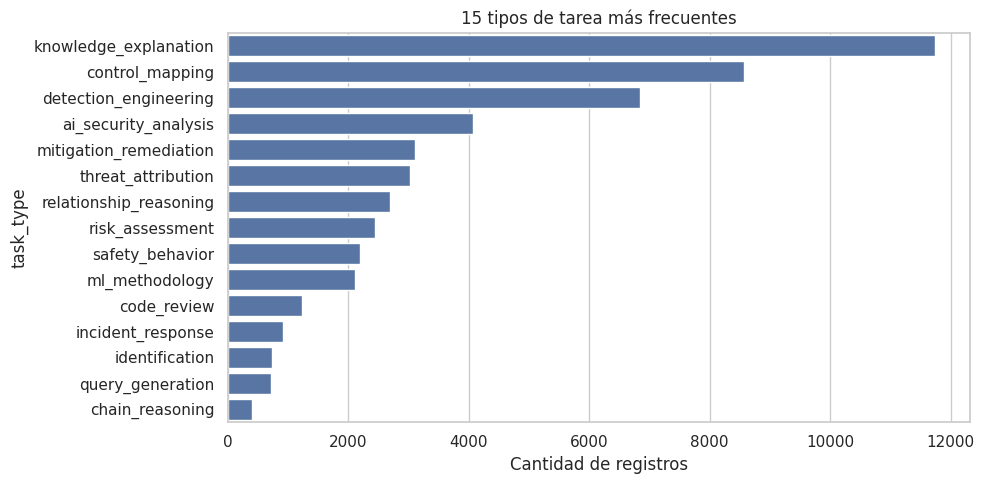

Subdominios más frecuentes:


,registros
subdomain,
detection_strategy,4318
ai_threat,4186
defensive_reframe,2184
evaluation,2096
logsource_mapping,1956
weakness_relationships,1348
prioritisation,1346
pattern_overview,1331
family_overview,1308


In [9]:
print("Tipos de tarea (task_type):")
tabla_task = df_all["task_type"].value_counts().to_frame("registros")
tabla_task["porcentaje"] = (tabla_task["registros"] / len(df_all) * 100).round(2)
display(tabla_task)

plt.figure(figsize=(10, 5))
sns.barplot(x=tabla_task.head(15)["registros"].values, y=tabla_task.head(15).index, orient="h")
plt.title("15 tipos de tarea más frecuentes")
plt.xlabel("Cantidad de registros")
plt.ylabel("task_type")
plt.tight_layout()
plt.show()

print("Subdominios más frecuentes:")
display(df_all["subdomain"].value_counts().head(15).to_frame("registros"))

### Explicación del bloque: tipos de tarea y subdominios
Se cuentan los valores de `task_type` y se calcula qué porcentaje representa cada tipo de solicitud. La gráfica muestra los 15 tipos más frecuentes, mientras que la tabla final lista los subdominios más comunes. Estas variables sirven para comprender la variedad del dataset; son descriptivas y no se concatenan al texto que recibe BERT.

difficulty,advanced,beginner,intermediate
domain,,,
ai_ml_security,68,206,4328
attack_knowledge,1515,695,677
cloud_security,1285,90,869
cryptography,83,1259,758
defense_engineering,1176,109,1701
detection_engineering,6396,23,1551
governance_risk,2666,0,510
identity_access,1246,167,891
incident_response,2147,0,796


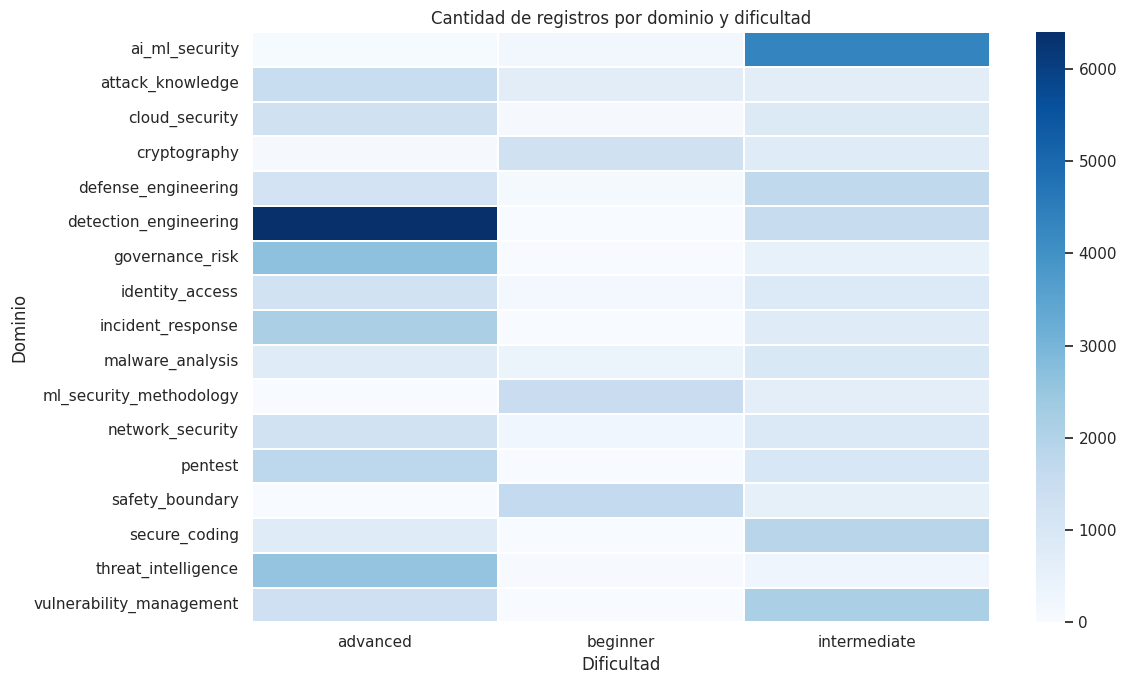

In [10]:
# Relación entre dificultad y dominio.
tabla_dificultad = pd.crosstab(df_all["domain"], df_all["difficulty"])
display(tabla_dificultad)

plt.figure(figsize=(12, 7))
sns.heatmap(tabla_dificultad, cmap="Blues", annot=False, linewidths=0.2)
plt.title("Cantidad de registros por dominio y dificultad")
plt.xlabel("Dificultad")
plt.ylabel("Dominio")
plt.tight_layout()
plt.show()

### Explicación del bloque: dificultad por dominio
`pd.crosstab` construye una tabla que cruza cada dominio con los niveles de dificultad. El mapa de calor representa visualmente la cantidad de registros en cada combinación. Esto permite observar si ciertos dominios concentran más solicitudes de determinada dificultad. La dificultad se utiliza únicamente para caracterizar el dataset, no como entrada ni como etiqueta del modelo.

In [11]:
# Ejemplos reales del mensaje del usuario en distintos dominios.
for dominio in clases:
    muestra = train_df[train_df["domain"] == dominio].sample(
        n=1, random_state=SEED
    ).iloc[0]
    print("\n" + "=" * 95)
    print("DOMINIO:", dominio)
    print("SUBDOMINIO:", muestra.get("subdomain", "No disponible"))
    print("TIPO DE TAREA:", muestra.get("task_type", "No disponible"))
    print("SOLICITUD DEL USUARIO:")
    print(muestra["text"][:900])


DOMINIO: ai_ml_security
SUBDOMINIO: ai_threat
TIPO DE TAREA: ai_security_analysis
SOLICITUD DEL USUARIO:
I am reading the paper "Agent Smith: A Single Image Can Jailbreak One Million Multimodal LLM Agents Exponentially Fast" (arXiv:2402.08567v2). Its section "Related Work" is the part I need to understand. Explain it in depth - the claims, the method, the evidence and the caveats - and say what a security practitioner should take away from it.

This is part 7 of 8; answer only that part, continuing where the previous part stopped.

Cover all of the following in depth, and stay concrete:
- Experiments
- Conclusion

DOMINIO: attack_knowledge
SUBDOMINIO: pattern_overview
TIPO DE TAREA: knowledge_explanation
SOLICITUD DEL USUARIO:
Explain CAPEC-407 (Pretexting). What is the attack pattern and how severe is it?

Cover all of the following in depth, and stay concrete:
- Definition
- Classification

Then add a reference appendix: related records from the same corpus that a practitioner would

### Explicación del bloque: ejemplos de solicitudes
El ciclo selecciona una pregunta de entrenamiento por cada dominio y muestra su dominio, subdominio y tipo de tarea. La semilla fija hace que la muestra sea reproducible. Revisar ejemplos concretos ayuda a entender qué lenguaje y qué variedad temática debe aprender el clasificador, y permite comprobar de forma cualitativa que el texto extraído corresponde al mensaje del usuario.

### Interpretación del EDA

El dataset es apropiado para una tarea de clasificación multiclase porque ofrece una etiqueta temática explícita (`domain`) y una entrada textual explícita en el mensaje `user`. A diferencia de una colección sin etiquetas, no es necesario inventar categorías: el objetivo de aprendizaje se toma directamente de los metadatos de la fuente.

La tarjeta consultada presenta 51.805 registros globales y tres particiones independientes. El notebook vuelve a calcular las cantidades descargadas y la distribución por dominio para que el informe refleje exactamente la versión usada. La distribución de las clases debe interpretarse mediante la tabla y la gráfica producidas arriba: aunque cada dominio tiene un volumen considerable, no se debe asumir que las clases están perfectamente balanceadas.

La variable `task_type` describe la forma de la solicitud y `subdomain` representa una subdivisión temática. Se muestran como variables descriptivas para comprender la variedad del conjunto, pero se excluyen del texto de entrada y de la etiqueta. La variable `difficulty` también se analiza únicamente para caracterizar los registros.

Cada ejemplo del EDA muestra la pregunta del usuario junto con su dominio y subdominio. Esto permite observar qué tipo de lenguaje recibirá BERT y cómo se relaciona la pregunta con la categoría. La respuesta del asistente no se utiliza: suele ser mucho más larga que la pregunta y puede contener encabezados o referencias que revelen directamente la temática.

La tarjeta indica que los grupos de origen se distribuyeron mediante `group_key`, y el notebook verifica los cruces entre `train`, `validation` y `test`. También comprueba preguntas idénticas entre particiones. Estas auditorías son importantes porque una pregunta repetida o un mismo grupo de origen en entrenamiento y prueba podría inflar las métricas.

El conjunto tiene una limitación de procedencia que debe quedar explícita: es `mixed-per-source`, no una colección con una única licencia global. Además, la tarjeta advierte que una parte de las respuestas tiene apéndices de referencias reutilizados y que los registros no fueron revisados individualmente por expertos. Como el modelo solo recibe la pregunta del usuario, se evita aprender directamente de esos apéndices, pero no se elimina toda posible dependencia entre registros derivados de una misma fuente.

## 7. Tokenización y longitud de los textos

BERT no recibe cadenas directamente. El tokenizador WordPiece convierte cada pregunta en identificadores y máscaras de atención. Se fija `MAX_LENGTH=256` para equilibrar cobertura del texto, memoria y tiempo de entrenamiento. La proporción de preguntas que supera el límite se calcula con el tokenizador real, no mediante el conteo de palabras ni mediante los tokens `cl100k_base` de la tarjeta.

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Longitud de preguntas (palabras):


,longitud_caracteres,longitud_palabras
count,51805.00,51805.00
mean,458.18,73.68
std,114.33,18.85
min,185.00,32.00
25%,395.00,64.00
50%,438.00,71.00
75%,488.00,78.00
max,3062.00,505.00


Preguntas que superan 256 tokens BERT: 406 de 51,805 (0.78 %)
Porcentaje de truncamiento por dominio:


,porcentaje
domain,
secure_coding,3.65
cryptography,3.33
ai_ml_security,2.43
ml_security_methodology,1.80
safety_boundary,1.36
identity_access,0.82
governance_risk,0.72
cloud_security,0.45
network_security,0.21


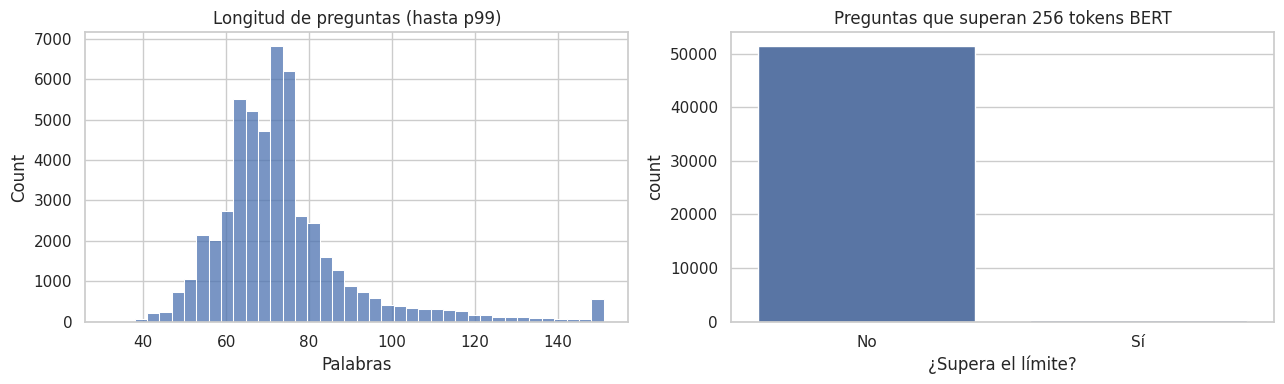

In [12]:
CHECKPOINT = "bert-base-uncased"
MAX_LENGTH = 256

# Limitar el modelo al uso académico de texto en inglés, acorde con la tarjeta del dataset.
tokenizer = AutoTokenizer.from_pretrained(CHECKPOINT)

df_all["longitud_caracteres"] = df_all["text"].str.len()
df_all["longitud_palabras"] = df_all["text"].str.split().str.len()

longitudes_wordpiece = []
for inicio in range(0, len(df_all), 128):
    lote = df_all["text"].iloc[inicio:inicio + 128].tolist()
    tok = tokenizer(lote, truncation=True, max_length=MAX_LENGTH + 1, padding=False)
    longitudes_wordpiece.extend(len(ids) for ids in tok["input_ids"])

df_all["tokens_bert_hasta_257"] = longitudes_wordpiece
df_all["supera_max_length"] = df_all["tokens_bert_hasta_257"] > MAX_LENGTH
n_truncados = int(df_all["supera_max_length"].sum())
pct_truncados = n_truncados / len(df_all) * 100

print("Longitud de preguntas (palabras):")
display(df_all[["longitud_caracteres", "longitud_palabras"]].describe().round(2))
print(f"Preguntas que superan {MAX_LENGTH} tokens BERT: {n_truncados:,} de {len(df_all):,} ({pct_truncados:.2f} %)")
print("Porcentaje de truncamiento por dominio:")
tabla_truncamiento = df_all.groupby("domain")["supera_max_length"].mean().mul(100).sort_values(ascending=False).to_frame("porcentaje")
display(tabla_truncamiento.round(2))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(df_all["longitud_palabras"].clip(upper=df_all["longitud_palabras"].quantile(0.99)), bins=40, ax=axes[0])
axes[0].set_title("Longitud de preguntas (hasta p99)")
axes[0].set_xlabel("Palabras")
sns.countplot(data=df_all, x="supera_max_length", ax=axes[1])
axes[1].set_title("Preguntas que superan 256 tokens BERT")
axes[1].set_xlabel("¿Supera el límite?")
axes[1].set_xticklabels(["No", "Sí"])
plt.tight_layout()
plt.show()

### Explicación del bloque: tokenizador y longitud máxima
Se carga el tokenizador de `bert-base-uncased`, que divide el texto en unidades WordPiece y convierte esas unidades en identificadores. `MAX_LENGTH = 256` establece el máximo de tokens por pregunta. La celda calcula longitudes y detecta cuántos textos superarían ese límite usando el propio tokenizador de BERT. Cuando una pregunta excede 256 tokens, el procesamiento posterior la trunca; por eso se cuantifica qué proporción podría perder parte del final.

### Interpretación de la longitud y del truncamiento

La longitud de una pregunta no equivale a la longitud de su respuesta. La tarjeta de HolyCyber indica que el registro completo (mensaje de usuario más respuesta del asistente) tiene al menos 2.000 tokens, pero este proyecto procesa exclusivamente el mensaje del usuario. Por esa razón, la longitud debe calcularse sobre el texto que realmente se entrega a BERT.

El porcentaje impreso arriba mide qué proporción de preguntas supera 256 tokens WordPiece. Es una medida directa del posible truncamiento. Si el porcentaje es elevado, parte del contenido al final de las preguntas no llegará al modelo. Como trabajo futuro se pueden comparar límites de 384 o 512 tokens, o estrategias de ventanas, teniendo en cuenta el coste de memoria y entrenamiento.

## 8. Preparación de datasets para BERT

Se codifican las 17 categorías con identificadores enteros. Se utilizan las particiones oficiales: `train` para ajustar los pesos, `validation` para seleccionar hiperparámetros y `test` para una evaluación final independiente.

In [13]:
label2id = {nombre: i for i, nombre in enumerate(clases)}
id2label = {i: nombre for nombre, i in label2id.items()}
NUM_LABELS = len(clases)


def convertir_a_dataset(frame):
    base = frame[["text", "domain"]].copy()
    base["labels"] = base["domain"].map(label2id).astype(int)
    return Dataset.from_pandas(base[["text", "labels"]], preserve_index=False)


def tokenizar_lote(batch):
    return tokenizer(batch["text"], truncation=True, max_length=MAX_LENGTH)

train_hf = convertir_a_dataset(train_df)
val_hf = convertir_a_dataset(val_df)
test_hf = convertir_a_dataset(test_df)

tokenized_train = train_hf.map(tokenizar_lote, batched=True, remove_columns=["text"])
tokenized_val = val_hf.map(tokenizar_lote, batched=True, remove_columns=["text"])
tokenized_test = test_hf.map(tokenizar_lote, batched=True, remove_columns=["text"])

data_collator = DataCollatorWithPadding(tokenizer=tokenizer)
print(tokenized_train)
print("Ejemplo tokenizado:")
display(tokenized_train[0])

Map:   0%|          | 0/40998 [00:00<?, ? examples/s]

Map:   0%|          | 0/5105 [00:00<?, ? examples/s]

Map:   0%|          | 0/5702 [00:00<?, ? examples/s]

Dataset({
    features: ['labels', 'input_ids', 'token_type_ids', 'attention_mask'],
    num_rows: 40998
})
Ejemplo tokenizado:


{'labels': 15,
 'input_ids': [101,
  7680,
  7849,
  5562,
  1996,
  2012,
  2102,
  1004,
  23616,
  3049,
  22478,
  1006,
  1039,
  8889,
  24096,
  1007,
  1012,
  3104,
  2035,
  1997,
  1996,
  2206,
  1999,
  5995,
  1010,
  1998,
  2994,
  5509,
  1024,
  1011,
  19184,
  1011,
  5461,
  5159,
  1011,
  2034,
  1013,
  2197,
  2464,
  2059,
  5587,
  1037,
  4431,
  22524,
  1024,
  3141,
  2636,
  2013,
  1996,
  2168,
  13931,
  2008,
  1037,
  18742,
  2052,
  2215,
  3875,
  2023,
  3437,
  1010,
  4415,
  4417,
  2004,
  4431,
  3430,
  1012,
  102],
 'token_type_ids': [0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0,
  0],
 'attention_mask': [1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1,
  1

### Explicación del bloque: codificación y preparación para BERT
`label2id` transforma cada uno de los 17 nombres de dominio en un entero, porque el modelo necesita etiquetas numéricas. `id2label` permite convertir luego esos números a nombres legibles. `convertir_a_dataset` conserva únicamente el texto y la etiqueta codificada. Después, `tokenizar_lote` aplica el tokenizador con truncamiento y longitud máxima. Finalmente se procesan las tres particiones y `DataCollatorWithPadding` completa dinámicamente los lotes para que las secuencias de un mismo lote tengan una longitud compatible.

## 9. Métricas y definición del modelo

La cabeza de clasificación de BERT produce una puntuación por cada dominio. Se utiliza `argmax` para obtener la clase predicha. La métrica principal es F1 macro; también se informa F1 ponderado, accuracy, precision macro y recall macro.

In [14]:
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)
    precision, recall, f1_macro, _ = precision_recall_fscore_support(
        labels, predictions, average="macro", zero_division=0
    )
    _, _, f1_weighted, _ = precision_recall_fscore_support(
        labels, predictions, average="weighted", zero_division=0
    )
    return {
        "accuracy": accuracy_score(labels, predictions),
        "precision_macro": precision,
        "recall_macro": recall,
        "f1_macro": f1_macro,
        "f1_weighted": f1_weighted,
    }


def crear_modelo():
    return AutoModelForSequenceClassification.from_pretrained(
        CHECKPOINT,
        num_labels=NUM_LABELS,
        id2label=id2label,
        label2id=label2id,
    )

# Pesos inversamente proporcionales a las frecuencias de la partición train.
y_train_completo = train_df["domain"].map(label2id).to_numpy()
clases_ids = np.arange(NUM_LABELS)
class_weights = compute_class_weight(
    class_weight="balanced",
    classes=clases_ids,
    y=y_train_completo,
)
print("Pesos por dominio:")
display(pd.DataFrame({"domain": [id2label[i] for i in clases_ids], "class_weight": class_weights}).sort_values("class_weight", ascending=False))

Pesos por dominio:


,domain,class_weight
3,cryptography,1.478631
10,ml_security_methodology,1.467831
9,malware_analysis,1.440649
13,safety_boundary,1.394016
2,cloud_security,1.374941
7,identity_access,1.339804
11,network_security,1.286212
14,secure_coding,1.118056
12,pentest,1.111358
8,incident_response,1.056813


### Explicación del bloque: métricas y arquitectura de clasificación
`compute_metrics` recibe los logits que produce el modelo y las etiquetas reales. `argmax` selecciona para cada ejemplo la clase con mayor puntuación. Se calculan accuracy, precisión macro, recall macro, F1 macro y F1 ponderado. F1 macro da el mismo peso a cada dominio, mientras F1 ponderado considera el número de ejemplos de cada clase. `crear_modelo` carga BERT con una cabeza de clasificación configurada para las 17 categorías. También se calculan pesos inversos a la frecuencia para poder probar una pérdida que compense el desbalance.

## 10. Experimentación de hiperparámetros

Entrenar BERT con las 41 mil preguntas en cada prueba de hiperparámetros puede consumir bastante tiempo. Por ello, los experimentos comparativos se realizan por defecto con una muestra estratificada de hasta 12.000 preguntas de entrenamiento y se evalúan en toda la partición de validación. Una vez seleccionada la configuración, el modelo definitivo se vuelve a entrenar con `train + validation` completos y se evalúa en `test`.

Se comparan learning rate, batch size, número de épocas y pérdida estándar frente a pérdida ponderada por clase. La partición de prueba no se utiliza para seleccionar configuraciones.

In [15]:
MAX_TRAIN_SAMPLES_TUNING = 12000  # Usa None para entrenar cada experimento con todo train.

if MAX_TRAIN_SAMPLES_TUNING is not None and len(train_df) > MAX_TRAIN_SAMPLES_TUNING:
    train_tune_df, _ = train_test_split(
        train_df,
        train_size=MAX_TRAIN_SAMPLES_TUNING,
        random_state=SEED,
        stratify=train_df["domain"],
    )
    train_tune_df = train_tune_df.reset_index(drop=True)
else:
    train_tune_df = train_df.copy()

train_tune_hf = convertir_a_dataset(train_tune_df)
tokenized_train_tune = train_tune_hf.map(tokenizar_lote, batched=True, remove_columns=["text"])
print(f"Ejemplos para ajuste de hiperparámetros: {len(train_tune_df):,} de {len(train_df):,}")
print(f"Validación utilizada en cada experimento: {len(val_df):,}")

Map:   0%|          | 0/12000 [00:00<?, ? examples/s]

Ejemplos para ajuste de hiperparámetros: 12,000 de 40,998
Validación utilizada en cada experimento: 5,105


### Explicación del bloque: muestra para ajustar hiperparámetros
Para reducir el tiempo de los experimentos, se seleccionan hasta 12.000 ejemplos de entrenamiento mediante muestreo estratificado. Esto conserva aproximadamente la proporción de los dominios. Si se cambia `MAX_TRAIN_SAMPLES_TUNING` a `None`, se utiliza todo el conjunto de entrenamiento en cada experimento. La validación completa se mantiene igual para que las configuraciones se comparen en las mismas condiciones.

> **Importante sobre los experimentos:** antes de iniciar cada configuración se elimina únicamente su carpeta de salida anterior (`resultados_holycyber/<experimento>`). Así se evita mezclar checkpoints viejos con los nuevos. `load_best_model_at_end=True` se conserva: al finalizar cada experimento se restaurará el mejor checkpoint medido por `f1_macro` en validación.

In [16]:
class WeightedLossTrainer(Trainer):
    """Trainer con entropía cruzada ponderada para clases desbalanceadas."""
    def __init__(self, *args, class_weights, **kwargs):
        super().__init__(*args, **kwargs)
        self.class_weights = torch.tensor(class_weights, dtype=torch.float32)
        self.model_accepts_loss_kwargs = False

    def compute_loss(self, model, inputs, return_outputs=False, num_items_in_batch=None):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        weights = self.class_weights.to(device=outputs.logits.device, dtype=outputs.logits.dtype)
        loss = torch.nn.functional.cross_entropy(outputs.logits, labels, weight=weights)
        return (loss, outputs) if return_outputs else loss


EXPERIMENTOS = [
    {"nombre": "E1_lr2e-5_bs16_ep2", "learning_rate": 2e-5, "batch_size": 16, "epochs": 2, "loss": "standard"},
    {"nombre": "E2_lr3e-5_bs16_ep2", "learning_rate": 3e-5, "batch_size": 16, "epochs": 2, "loss": "standard"},
    {"nombre": "E3_lr2e-5_bs32_ep2", "learning_rate": 2e-5, "batch_size": 32, "epochs": 2, "loss": "standard"},
    {"nombre": "E4_lr2e-5_bs16_ep2_weighted", "learning_rate": 2e-5, "batch_size": 16, "epochs": 2, "loss": "weighted"},
    {"nombre": "E5_lr5e-5_bs16_ep2", "learning_rate": 5e-5, "batch_size": 16, "epochs": 2, "loss": "standard"},
]


def crear_argumentos(config, output_dir):
    return TrainingArguments(
        output_dir=output_dir,
        learning_rate=config["learning_rate"],
        per_device_train_batch_size=config["batch_size"],
        per_device_eval_batch_size=32,
        num_train_epochs=config["epochs"],
        weight_decay=0.01,
        eval_strategy="epoch",
        save_strategy="epoch",
        logging_strategy="epoch",
        load_best_model_at_end=True,
        metric_for_best_model="f1_macro",
        greater_is_better=True,
        save_total_limit=1,
        fp16=torch.cuda.is_available(),
        report_to="none",
        seed=SEED,
        data_seed=SEED,
    )


def crear_trainer_experimento(config):
    set_seed(SEED)
    # Evitar que checkpoints de ejecuciones anteriores contaminen el experimento actual.
    output_dir = f"./resultados_holycyber/{config['nombre']}"
    if os.path.isdir(output_dir):
        shutil.rmtree(output_dir)
    model = crear_modelo()
    args = crear_argumentos(config, output_dir)
    kwargs = dict(
        model=model,
        args=args,
        train_dataset=tokenized_train_tune,
        eval_dataset=tokenized_val,
        processing_class=tokenizer,
        data_collator=data_collator,
        compute_metrics=compute_metrics,
    )
    if config["loss"] == "weighted":
        return WeightedLossTrainer(**kwargs, class_weights=class_weights)
    return Trainer(**kwargs)

### Explicación del bloque: pérdida ponderada y configuraciones
`WeightedLossTrainer` extiende el `Trainer` de Hugging Face y reemplaza la pérdida estándar por entropía cruzada ponderada. Las clases menos frecuentes reciben un peso mayor, buscando que el modelo no las ignore. La lista `EXPERIMENTOS` define cinco combinaciones de learning rate, batch size, épocas y tipo de pérdida. `crear_argumentos` configura evaluación por época, guardado del mejor checkpoint según F1 macro y uso de precisión mixta si existe GPU. `crear_trainer_experimento` crea un modelo nuevo para cada configuración.

In [17]:
resultados_experimentos = []

for config in EXPERIMENTOS:
    print("\n" + "=" * 95)
    print("INICIANDO:", config["nombre"])
    print("=" * 95)

    trainer_exp = crear_trainer_experimento(config)
    trainer_exp.train()
    metricas_val = trainer_exp.evaluate()

    resultados_experimentos.append({
        "experimento": config["nombre"],
        "learning_rate": config["learning_rate"],
        "batch_size": config["batch_size"],
        "epocas": config["epochs"],
        "loss": config["loss"],
        "accuracy_validacion": metricas_val.get("eval_accuracy"),
        "precision_macro_validacion": metricas_val.get("eval_precision_macro"),
        "recall_macro_validacion": metricas_val.get("eval_recall_macro"),
        "f1_macro_validacion": metricas_val.get("eval_f1_macro"),
        "f1_weighted_validacion": metricas_val.get("eval_f1_weighted"),
        "mejor_checkpoint": trainer_exp.state.best_model_checkpoint,
    })

    del trainer_exp
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

resultados_df = pd.DataFrame(resultados_experimentos).sort_values(
    "f1_macro_validacion", ascending=False
).reset_index(drop=True)
print("Resumen de experimentos:")
display(resultados_df)


INICIANDO: E1_lr2e-5_bs16_ep2


model.safetensors:   0%|          | 0.00/440M [00:00<?, ?B/s]

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at bert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Epoch,Training Loss,Validation Loss,Accuracy,Precision Macro,Recall Macro,F1 Macro,F1 Weighted
1,0.870300,0.329740,0.906954,0.904528,0.892978,0.893544,0.908308
2,0.237000,0.264042,0.925367,0.917069,0.917190,0.916076,0.926376



INICIANDO: E2_lr3e-5_bs16_ep2


Some weights of BertForSequenceClassification were not initialized from the model checkpoint at bert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


... (8 outputs left out)

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at bert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Epoch,Training Loss,Validation Loss,Accuracy,Precision Macro,Recall Macro,F1 Macro,F1 Weighted
1,0.587500,0.262682,0.931244,0.928983,0.923295,0.924296,0.932083
2,0.171800,0.245161,0.939471,0.934687,0.930256,0.931547,0.939634


Resumen de experimentos:


,experimento,learning_rate,batch_size,epocas,loss,accuracy_validacion,precision_macro_validacion,recall_macro_validacion,f1_macro_validacion,f1_weighted_validacion,mejor_checkpoint
0,E5_lr5e-5_bs16_ep2,0.00005,16,2,standard,0.939471,0.934687,0.930256,0.931547,0.939634,./resultados_holycyber/E5_lr5e-5_bs16_ep2/chec...
1,E2_lr3e-5_bs16_ep2,0.00003,16,2,standard,0.925955,0.917159,0.917378,0.916667,0.926825,./resultados_holycyber/E2_lr3e-5_bs16_ep2/chec...
2,E4_lr2e-5_bs16_ep2_weighted,0.00002,16,2,weighted,0.924780,0.914230,0.920435,0.916160,0.925887,./resultados_holycyber/E4_lr2e-5_bs16_ep2_weig...
3,E1_lr2e-5_bs16_ep2,0.00002,16,2,standard,0.925367,0.917069,0.917190,0.916076,0.926376,./resultados_holycyber/E1_lr2e-5_bs16_ep2/chec...
4,E3_lr2e-5_bs32_ep2,0.00002,32,2,standard,0.911655,0.904310,0.900719,0.900887,0.913543,./resultados_holycyber/E3_lr2e-5_bs32_ep2/chec...


### Explicación del bloque: ejecución de experimentos
El ciclo recorre las configuraciones definidas, crea un entrenador, ajusta el modelo y calcula sus métricas en validación. Se almacenan los hiperparámetros, resultados y ruta del mejor checkpoint. Después se libera memoria, especialmente la memoria de GPU. La tabla final ordena los experimentos por F1 macro de validación; esta métrica es el criterio principal para seleccionar la configuración, sin consultar el conjunto de prueba.

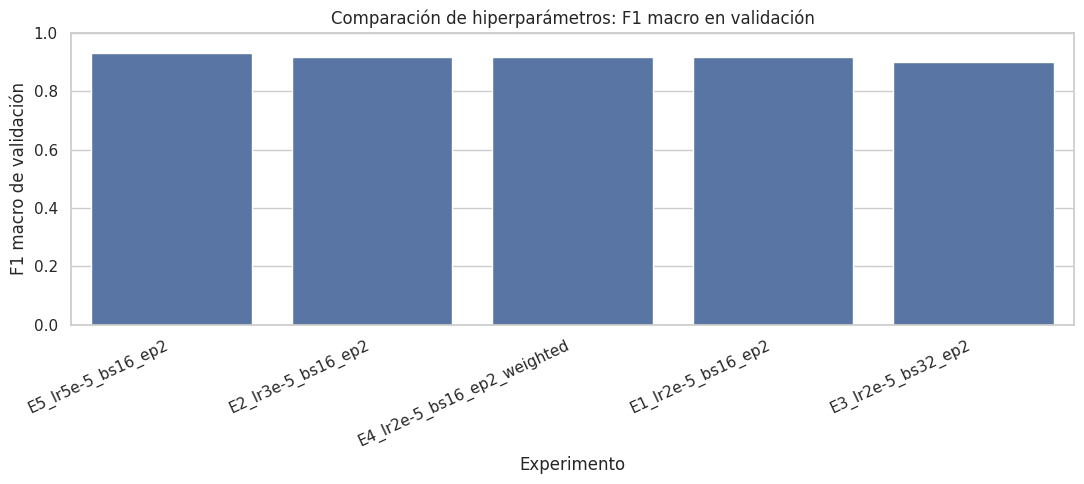

Mejor configuración seleccionada con validación:
{
  "nombre": "E5_lr5e-5_bs16_ep2",
  "learning_rate": 5e-05,
  "batch_size": 16,
  "epochs": 2,
  "loss": "standard"
}
F1 macro en validación: 0.9315


In [18]:
plt.figure(figsize=(11, 5))
sns.barplot(data=resultados_df, x="experimento", y="f1_macro_validacion")
plt.title("Comparación de hiperparámetros: F1 macro en validación")
plt.xlabel("Experimento")
plt.ylabel("F1 macro de validación")
plt.xticks(rotation=25, ha="right")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

mejor_nombre = resultados_df.loc[0, "experimento"]
mejor_config = next(x for x in EXPERIMENTOS if x["nombre"] == mejor_nombre)
print("Mejor configuración seleccionada con validación:")
print(json.dumps(mejor_config, indent=2, ensure_ascii=False))
print(f"F1 macro en validación: {resultados_df.loc[0, 'f1_macro_validacion']:.4f}")

### Explicación del bloque: selección de la mejor configuración
La gráfica compara el F1 macro de validación de cada experimento. La celda identifica el nombre de la configuración situada en primer lugar, recupera sus parámetros y los imprime. Esta selección se realiza con validación, no con test, para conservar una evaluación final independiente. Las diferencias pequeñas deben interpretarse con cautela porque los experimentos utilizan una sola semilla.

### Interpretación de la experimentación

La tabla y la gráfica permiten comparar las configuraciones en la misma partición de validación. La selección se realiza por F1 macro, no por accuracy, para evitar favorecer únicamente los dominios con más ejemplos. También se incluye una configuración con pérdida ponderada; sus pesos se calculan a partir de las frecuencias de `domain` en entrenamiento.

Los experimentos utilizan una muestra estratificada de entrenamiento para controlar el coste de cómputo. Por ello, sus métricas sirven para seleccionar una configuración de manera práctica, pero no deben confundirse con la evaluación final del modelo que se entrenará con todas las particiones `train + validation`. Se usa una semilla fija; la comparación no mide la variabilidad entre semillas y las diferencias pequeñas deben interpretarse con cautela.

## 11. Entrenamiento del modelo final

Se vuelve a inicializar BERT desde el checkpoint preentrenado y se entrena con todos los registros de `train + validation`. Se conservan el learning rate, el batch size, el número de épocas y el tipo de pérdida de la mejor configuración seleccionada. La partición `test` permanece separada y se utiliza solo para la evaluación final.

In [19]:
train_val_df = pd.concat([train_df, val_df], ignore_index=True)
train_val_hf = convertir_a_dataset(train_val_df)
tokenized_train_val = train_val_hf.map(tokenizar_lote, batched=True, remove_columns=["text"])

args_final = TrainingArguments(
    output_dir="./modelo_final_holycyber_entrenamiento",
    learning_rate=mejor_config["learning_rate"],
    per_device_train_batch_size=mejor_config["batch_size"],
    per_device_eval_batch_size=32,
    num_train_epochs=mejor_config["epochs"],
    weight_decay=0.01,
    eval_strategy="no",
    save_strategy="no",
    logging_strategy="epoch",
    fp16=torch.cuda.is_available(),
    report_to="none",
    seed=SEED,
    data_seed=SEED,
)

kwargs_final = dict(
    model=crear_modelo(),
    args=args_final,
    train_dataset=tokenized_train_val,
    data_collator=data_collator,
    processing_class=tokenizer,
)

if mejor_config["loss"] == "weighted":
    trainer_final = WeightedLossTrainer(**kwargs_final, class_weights=class_weights)
else:
    trainer_final = Trainer(**kwargs_final)

trainer_final.train()

Map:   0%|          | 0/46103 [00:00<?, ? examples/s]

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at bert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Step,Training Loss
2882,0.314600
5764,0.124200


TrainOutput(global_step=5764, training_loss=0.21938931255353813, metrics={'train_runtime': 829.4522, 'train_samples_per_second': 111.165, 'train_steps_per_second': 6.949, 'total_flos': 8379648676616490.0, 'train_loss': 0.21938931255353813, 'epoch': 2.0})

### Explicación del bloque: entrenamiento final
Una vez elegidos los hiperparámetros, se concatenan `train` y `validation` para aprovechar todos esos registros en el entrenamiento definitivo. Se tokeniza el conjunto combinado y se construyen los argumentos con la mejor configuración encontrada. Se crea un modelo BERT nuevo y se entrena sin utilizar `test`. Si la configuración ganadora usa pérdida ponderada, se mantiene ese mismo criterio en el entrenamiento final.

## 12. Evaluación final en el conjunto de prueba

Se evalúa el modelo final con los 5.702 registros de prueba (o con el tamaño real descargado). Se reportan métricas globales, métricas por dominio y matriz de confusión. El conjunto de prueba no intervino en la selección de hiperparámetros.

In [20]:
predicciones_test = trainer_final.predict(tokenized_test)
logits_test = predicciones_test.predictions
y_true = predicciones_test.label_ids
y_pred = np.argmax(logits_test, axis=-1)

metricas_test = compute_metrics((logits_test, y_true))
print("Métricas finales en test:")
for nombre, valor in metricas_test.items():
    print(f"{nombre}: {valor:.4f}")

print("\nReporte de clasificación por dominio:")
print(classification_report(
    y_true,
    y_pred,
    labels=list(range(NUM_LABELS)),
    target_names=[id2label[i] for i in range(NUM_LABELS)],
    zero_division=0,
    digits=4,
))

reporte_dict = classification_report(
    y_true,
    y_pred,
    labels=list(range(NUM_LABELS)),
    target_names=[id2label[i] for i in range(NUM_LABELS)],
    zero_division=0,
    output_dict=True,
)
reporte_df = pd.DataFrame(reporte_dict).T

Métricas finales en test:
accuracy: 0.9421
precision_macro: 0.9430
recall_macro: 0.9381
f1_macro: 0.9401
f1_weighted: 0.9428

Reporte de clasificación por dominio:
                          precision    recall  f1-score   support

          ai_ml_security     0.7408    0.8201    0.7785       467
        attack_knowledge     0.9956    0.9956    0.9956       225
          cloud_security     0.9577    0.9784    0.9680       278
            cryptography     0.8841    0.8870    0.8856       301
     defense_engineering     1.0000    1.0000    1.0000       334
   detection_engineering     0.9988    0.9920    0.9954       870
         governance_risk     0.9459    0.8559    0.8986       347
         identity_access     0.9888    0.9466    0.9673       281
       incident_response     1.0000    1.0000    1.0000       360
        malware_analysis     0.9620    0.9124    0.9365       194
 ml_security_methodology     0.7430    0.7283    0.7356       254
        network_security     0.9882    0.97

### Explicación del bloque: evaluación final
El modelo predice las etiquetas del conjunto `test`. Los logits se convierten en clases mediante `argmax` y se comparan con las etiquetas reales. Se calculan las métricas globales y el reporte por dominio, que incluye precisión, recall, F1 y soporte. Esta es la medición final porque `test` no participó en la selección de hiperparámetros.

## 13. Baseline clásico: TF-IDF + regresión logística

Para contextualizar el rendimiento de BERT, se entrena un baseline clásico de NLP: TF-IDF con unigramas y bigramas, seguido de regresión logística multiclase con `class_weight="balanced"`. El baseline se entrena con `train + validation` y se evalúa con el mismo conjunto `test`. La comparación permite comprobar si el fine-tuning de BERT aporta una mejora respecto a un clasificador textual tradicional.

In [21]:
baseline_tfidf = Pipeline([
    ("tfidf", TfidfVectorizer(
        lowercase=True,
        strip_accents="unicode",
        ngram_range=(1, 2),
        min_df=2,
        max_features=50000,
        sublinear_tf=True,
    )),
    ("clasificador", LogisticRegression(
        class_weight="balanced",
        max_iter=3000,
        C=1.0,
        random_state=SEED,
    )),
])

baseline_tfidf.fit(train_val_df["text"], train_val_df["domain"])
pred_tfidf = baseline_tfidf.predict(test_df["text"])

metricas_tfidf = {
    "accuracy": accuracy_score(test_df["domain"], pred_tfidf),
    "precision_macro": precision_recall_fscore_support(test_df["domain"], pred_tfidf, average="macro", zero_division=0)[0],
    "recall_macro": precision_recall_fscore_support(test_df["domain"], pred_tfidf, average="macro", zero_division=0)[1],
    "f1_macro": f1_score(test_df["domain"], pred_tfidf, average="macro"),
    "f1_weighted": f1_score(test_df["domain"], pred_tfidf, average="weighted"),
}
print("Resultados del baseline TF-IDF:")
for k, v in metricas_tfidf.items():
    print(f"{k}: {v:.4f}")

Resultados del baseline TF-IDF:
accuracy: 0.9128
precision_macro: 0.9191
recall_macro: 0.9097
f1_macro: 0.9108
f1_weighted: 0.9152


### Explicación del bloque: baseline TF-IDF
Se crea un modelo tradicional para tener un punto de comparación. `TfidfVectorizer` convierte el texto en características numéricas según la importancia de palabras individuales y pares de palabras (unigramas y bigramas). Luego, una regresión logística multiclase realiza la clasificación; `class_weight="balanced"` compensa el desbalance de clases. El baseline se entrena con `train + validation` y se evalúa exactamente sobre `test`, igual que BERT.

## 14. Comparación de modelos y matriz de confusión

Se comparan los resultados de BERT y TF-IDF sobre el mismo conjunto de prueba. La selección del modelo principal se hizo previamente con validación; no se cambia el modelo a partir del resultado del conjunto de prueba.

,accuracy,precision_macro,recall_macro,f1_macro,f1_weighted
modelo,,,,,
BERT fine-tuning,0.9421,0.9430,0.9381,0.9401,0.9428
TF-IDF + regresión logística balanceada,0.9128,0.9191,0.9097,0.9108,0.9152


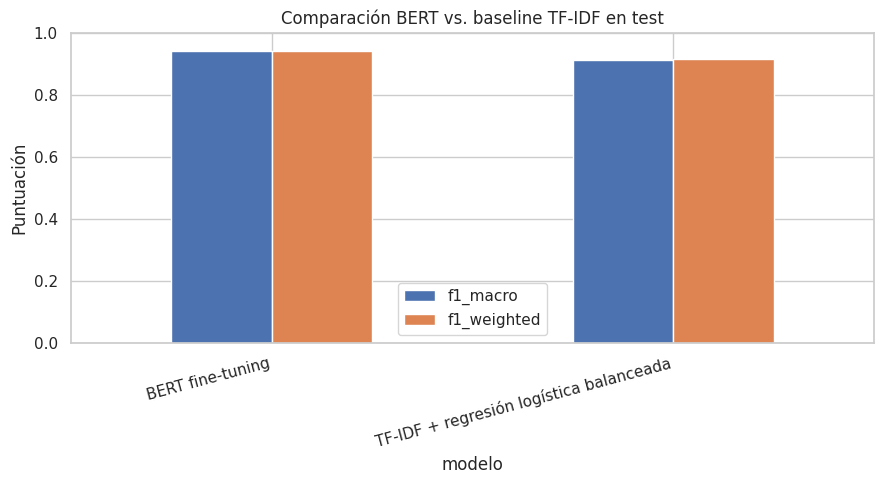

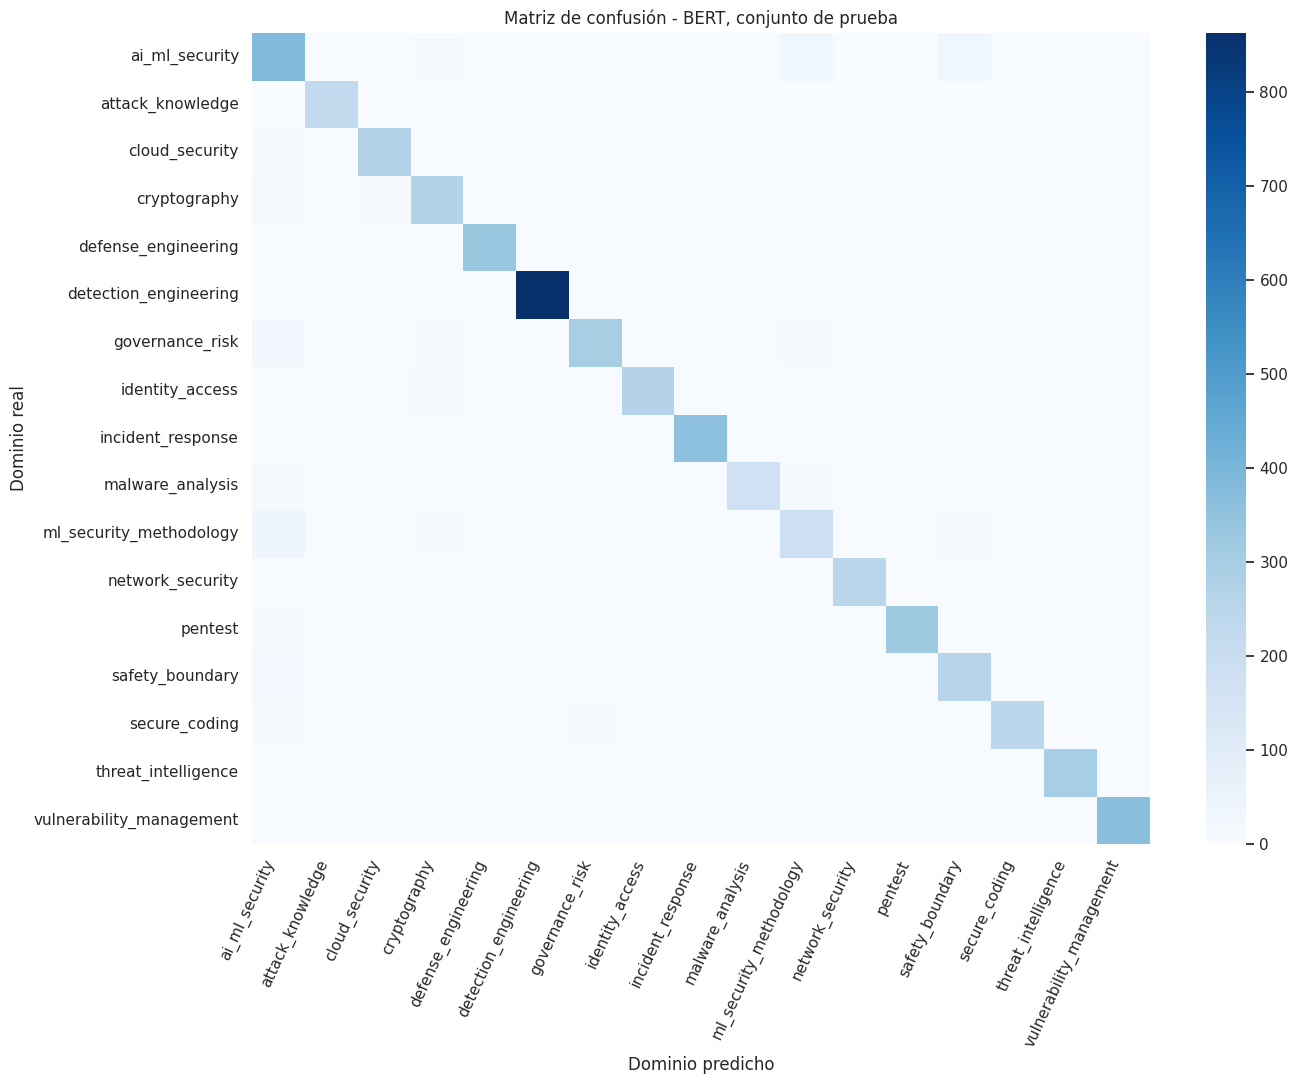

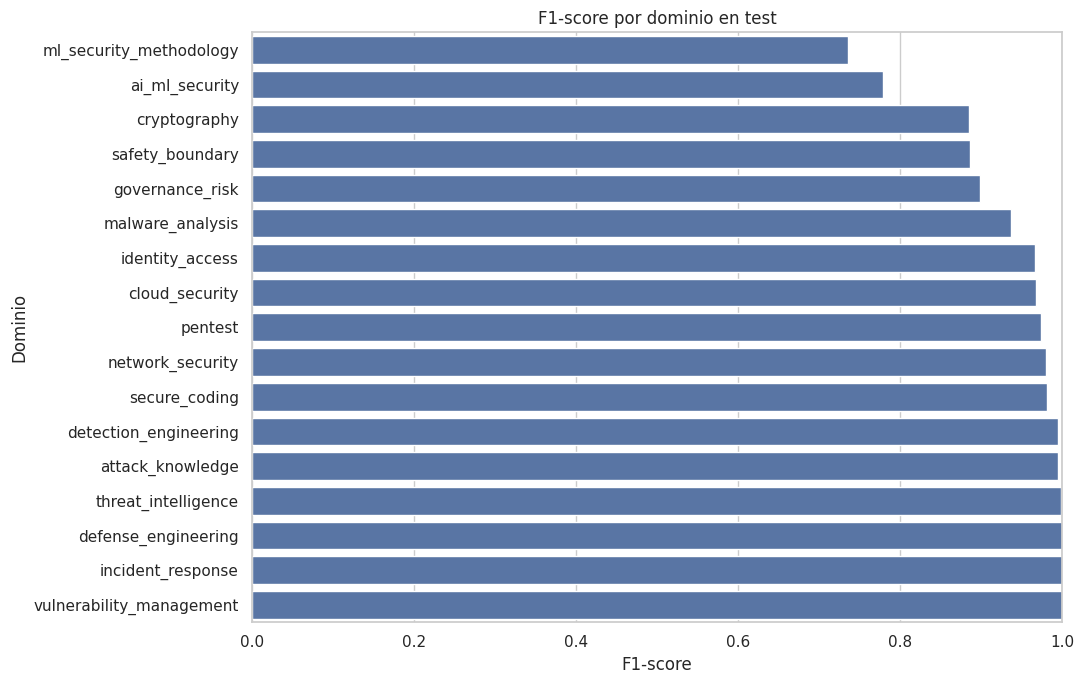

In [22]:
comparacion_modelos = pd.DataFrame([
    {"modelo": "BERT fine-tuning", **metricas_test},
    {"modelo": "TF-IDF + regresión logística balanceada", **metricas_tfidf},
]).set_index("modelo")
display(comparacion_modelos.round(4))

comparacion_modelos[["f1_macro", "f1_weighted"]].plot(kind="bar", figsize=(9, 5))
plt.title("Comparación BERT vs. baseline TF-IDF en test")
plt.ylabel("Puntuación")
plt.ylim(0, 1)
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

matriz = confusion_matrix(y_true, y_pred, labels=list(range(NUM_LABELS)))
plt.figure(figsize=(14, 11))
sns.heatmap(
    matriz,
    cmap="Blues",
    annot=False,
    xticklabels=[id2label[i] for i in range(NUM_LABELS)],
    yticklabels=[id2label[i] for i in range(NUM_LABELS)],
)
plt.title("Matriz de confusión - BERT, conjunto de prueba")
plt.xlabel("Dominio predicho")
plt.ylabel("Dominio real")
plt.xticks(rotation=65, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

f1_por_dominio = reporte_df.loc[[id2label[i] for i in range(NUM_LABELS)], "f1-score"].sort_values()
plt.figure(figsize=(11, 7))
sns.barplot(x=f1_por_dominio.values, y=f1_por_dominio.index, orient="h")
plt.title("F1-score por dominio en test")
plt.xlabel("F1-score")
plt.ylabel("Dominio")
plt.xlim(0, 1)
plt.tight_layout()
plt.show()

### Explicación del bloque: comparación y matriz de confusión
La tabla y la gráfica comparan BERT y TF-IDF usando métricas calculadas sobre el mismo conjunto de prueba. La matriz de confusión cruza dominio real y dominio predicho: los valores de la diagonal son aciertos y los valores fuera de ella muestran confusiones entre categorías. La última gráfica ordena los dominios por su F1, para identificar en cuáles funciona mejor o peor BERT. La conclusión debe basarse en los valores realmente obtenidos al ejecutar el notebook.

## 15. Análisis de errores

Se muestran ejemplos de preguntas cuyo dominio real no coincide con la predicción. El propósito es identificar dominios semánticamente cercanos, solicitudes que podrían encajar en más de una categoría o ejemplos cuya pregunta contiene poca información contextual. Los errores no se interpretan automáticamente como etiquetas incorrectas; requerirían revisión humana con los criterios de anotación de HolyCyber.

In [23]:
resultados_test = test_df.reset_index(drop=True).copy()
resultados_test["domain_real"] = [id2label[int(x)] for x in y_true]
resultados_test["domain_predicho"] = [id2label[int(x)] for x in y_pred]
resultados_test["correcto"] = resultados_test["domain_real"] == resultados_test["domain_predicho"]

errores = resultados_test[~resultados_test["correcto"]].copy()
print(f"Errores de clasificación: {len(errores):,} de {len(resultados_test):,} ({len(errores)/len(resultados_test):.2%})")
if len(errores):
    display(errores[["domain_real", "domain_predicho", "subdomain", "task_type", "text"]].head(15))
else:
    print("No se observaron errores en esta partición.")

print("Dominios con más errores:")
display(errores["domain_real"].value_counts().head(10).to_frame("errores"))

Errores de clasificación: 330 de 5,702 (5.79%)


,domain_real,domain_predicho,subdomain,task_type,text
516,attack_knowledge,threat_intelligence,pattern_execution,relationship_reasoning,How does ATT&CK S0298 Xbot nest in the wider t...
1585,detection_engineering,governance_risk,detection_strategy,detection_engineering,"I am reading the paper ""Integrated Solution Mo..."
1588,detection_engineering,cryptography,detection_strategy,detection_engineering,"I am reading the paper ""The process of macropr..."
1668,detection_engineering,ai_ml_security,detection_strategy,detection_engineering,"I am reading the paper ""A Logic Programming Ap..."
1669,detection_engineering,pentest,detection_strategy,detection_engineering,"I am reading the paper ""Approaches to Formal V..."
1670,detection_engineering,pentest,detection_strategy,detection_engineering,"I am reading the paper ""Approaches to Formal V..."
1671,detection_engineering,network_security,detection_strategy,detection_engineering,"I am reading the paper ""A security suite for w..."
1762,detection_engineering,cryptography,detection_strategy,detection_engineering,"I am reading the paper ""Hardware Implementatio..."
2146,ai_ml_security,governance_risk,ai_threat,ai_security_analysis,"I am reading the paper ""The process of macropr..."
2184,ai_ml_security,ml_security_methodology,ai_threat,ai_security_analysis,"I am reading the paper ""Android Malware Catego..."


Dominios con más errores:


,errores
domain_real,
ai_ml_security,84
ml_security_methodology,69
governance_risk,50
cryptography,34
safety_boundary,22
malware_analysis,17
identity_access,15
secure_coding,9
pentest,9


### Explicación del bloque: análisis de errores
Se construye una tabla que contiene la etiqueta real, la predicción y el texto de cada ejemplo. Después se filtran únicamente los casos incorrectos y se calcula cuántos errores hay y qué dominios acumulan más. Revisar estos casos permite encontrar categorías semánticamente cercanas o preguntas con poco contexto. Un error del modelo no demuestra por sí solo que la etiqueta del dataset sea incorrecta; sería necesaria una revisión humana.

## 16. Prueba con solicitudes nuevas

La siguiente función recibe una pregunta de ciberseguridad defensiva y devuelve el dominio predicho junto con las probabilidades estimadas para las principales clases. Las probabilidades son puntuaciones del modelo, no garantías de certeza. Para una solicitud que pertenezca a más de un dominio, el clasificador devuelve únicamente la clase con mayor puntuación.

In [24]:
device = trainer_final.model.device
trainer_final.model.eval()


def clasificar_solicitud(texto, top_k=3):
    if not isinstance(texto, str) or not texto.strip():
        raise ValueError("Ingresa una solicitud de texto no vacía.")
    entradas = tokenizer(
        texto,
        return_tensors="pt",
        truncation=True,
        max_length=MAX_LENGTH,
    ).to(device)
    with torch.no_grad():
        logits = trainer_final.model(**entradas).logits
        probabilidades = torch.softmax(logits, dim=-1).squeeze(0).cpu().numpy()
    indices = np.argsort(probabilidades)[::-1][:top_k]
    return {
        "solicitud": texto,
        "dominio_predicho": id2label[int(indices[0])],
        "top_k": [
            {"domain": id2label[int(i)], "probabilidad": float(probabilidades[i])}
            for i in indices
        ],
    }


solicitudes_demo = [
    "How can we detect suspicious PowerShell activity using endpoint telemetry and Sigma rules?",
    "What steps should an incident response team follow after a ransomware alert?",
    "How can I review an AWS account for excessive IAM permissions and exposed storage?",
    "Explain how to prioritize newly disclosed CVEs using severity and known exploitation evidence.",
]

for solicitud in solicitudes_demo:
    print(json.dumps(clasificar_solicitud(solicitud), indent=2, ensure_ascii=False))

{
  "solicitud": "How can we detect suspicious PowerShell activity using endpoint telemetry and Sigma rules?",
  "dominio_predicho": "ml_security_methodology",
  "top_k": [
    {
      "domain": "ml_security_methodology",
      "probabilidad": 0.727329432964325
    },
    {
      "domain": "ai_ml_security",
      "probabilidad": 0.19085019826889038
    },
    {
      "domain": "pentest",
      "probabilidad": 0.022244056686758995
    }
  ]
}
{
  "solicitud": "What steps should an incident response team follow after a ransomware alert?",
  "dominio_predicho": "safety_boundary",
  "top_k": [
    {
      "domain": "safety_boundary",
      "probabilidad": 0.5278005003929138
    },
    {
      "domain": "ml_security_methodology",
      "probabilidad": 0.31454911828041077
    },
    {
      "domain": "incident_response",
      "probabilidad": 0.08367343246936798
    }
  ]
}
{
  "solicitud": "How can I review an AWS account for excessive IAM permissions and exposed storage?",
  "dominio_predi

### Explicación del bloque: clasificación de solicitudes nuevas
`clasificar_solicitud` valida que la entrada no esté vacía, la tokeniza con el mismo límite usado durante el entrenamiento y la mueve al dispositivo donde está el modelo. `model.eval()` y `torch.no_grad()` indican que se realizará inferencia, no entrenamiento. `softmax` transforma los logits en puntuaciones normalizadas; se ordenan y se devuelven las principales categorías (`top_k`). Estas probabilidades expresan la confianza relativa del modelo, pero no son garantías de certeza.

## 17. Guardado del mejor modelo y resultados

Se guarda el modelo final, el tokenizador, la configuración, las métricas, el reporte por clase y la tabla de experimentos. El dataset original no se copia al repositorio. Dado que HolyCyber declara licencias mixtas por fuente, cualquier redistribución de filas o artefactos entrenados debe revisarse frente a las condiciones indicadas en la columna `license` y en las fuentes citadas.

In [25]:
CARPETA_MODELO = "./mejor_modelo_bert_holycyber"
os.makedirs(CARPETA_MODELO, exist_ok=True)
trainer_final.save_model(CARPETA_MODELO)
tokenizer.save_pretrained(CARPETA_MODELO)

metadata_modelo = {
    "dataset": DATASET_ID,
    "revision": DATASET_REVISION,
    "checkpoint_base": CHECKPOINT,
    "tarea": "clasificacion multiclase de solicitudes de ciberseguridad defensiva",
    "entrada": "messages[role=user].content",
    "variable_objetivo": "domain",
    "clases": id2label,
    "mejor_configuracion": mejor_config,
    "metricas_test_bert": {k: float(v) for k, v in metricas_test.items()},
    "metricas_test_tfidf": {k: float(v) for k, v in metricas_tfidf.items()},
    "max_length": MAX_LENGTH,
    "seed": SEED,
    "filas": {"train": len(train_df), "validation": len(val_df), "test": len(test_df)},
    "nota_licencia": "HolyCyber es mixed-per-source; comprobar license por fila/fuente antes de redistribuir datos o artefactos.",
}

with open(os.path.join(CARPETA_MODELO, "metadata.json"), "w", encoding="utf-8") as f:
    json.dump(metadata_modelo, f, ensure_ascii=False, indent=2)

resultados_df.to_csv("resultados_experimentos_holycyber.csv", index=False)
comparacion_modelos.to_csv("comparacion_modelos_holycyber.csv")
reporte_df.to_csv("reporte_por_dominio_holycyber.csv")
print("Modelo guardado en:", CARPETA_MODELO)
print("Archivos:", os.listdir(CARPETA_MODELO))
print("Tablas CSV generadas.")

Modelo guardado en: ./mejor_modelo_bert_holycyber
Archivos: ['vocab.txt', 'metadata.json', 'training_args.bin', 'tokenizer_config.json', 'tokenizer.json', 'config.json', 'special_tokens_map.json', 'model.safetensors']
Tablas CSV generadas.


### Explicación del bloque: guardado y trazabilidad
Se guarda el modelo ajustado y su tokenizador en una carpeta. También se crea `metadata.json` con la fuente y revisión del dataset, checkpoint base, tarea, clases, hiperparámetros, métricas, longitud máxima, semilla y cantidades por partición. Finalmente se exportan a CSV los experimentos, la comparación de modelos y el reporte por dominio. Esto facilita reutilizar el modelo y documentar cómo se obtuvo. La nota de licencia recuerda que HolyCyber tiene licencias mixtas por fuente.

## 18. Conclusiones del proyecto

El proyecto plantea una tarea supervisada de clasificación multiclase sobre solicitudes de ciberseguridad defensiva. La entrada del modelo es el mensaje del usuario (`messages` con `role=user`) y la etiqueta es `domain`, que contiene los 17 dominios definidos por HolyCyber. Se excluyeron del texto de entrada las respuestas del asistente y los metadatos que contienen la etiqueta, con el fin de evitar una fuga directa de información.

El análisis exploratorio permite caracterizar el volumen de registros, la distribución de dominios, la variedad de subdominios y tipos de tarea, la dificultad y la longitud de las solicitudes. Las particiones oficiales se conservan para respetar el diseño del dataset. La auditoría de `group_key` comprueba que los grupos de origen no se compartan entre entrenamiento, validación y prueba; también se revisan preguntas idénticas entre particiones.

La comparación de hiperparámetros se realiza con F1 macro en validación. Se incluyen learning rates, tamaños de lote, épocas y una alternativa con pérdida ponderada por clase. La configuración mejor posicionada en validación se utiliza para entrenar el modelo final con `train + validation`; la prueba se reserva para una única evaluación final. Al interpretar los resultados se deben considerar tanto F1 macro como F1 ponderado, accuracy y el rendimiento por cada dominio.

El baseline TF-IDF con regresión logística ofrece un punto de referencia tradicional. Si BERT supera al baseline en F1 macro, los resultados respaldan el valor añadido del fine-tuning contextual para esta tarea. Si las diferencias son pequeñas, no debe afirmarse que BERT sea superior de forma concluyente sin repetir el experimento con varias semillas o intervalos de confianza.

Entre las limitaciones se encuentran el truncamiento a 256 tokens, el uso de una sola semilla, la posible cercanía semántica entre dominios y la advertencia de la tarjeta sobre párrafos de referencia reutilizados en algunas respuestas. Aunque la entrada del modelo es únicamente el mensaje del usuario, las métricas no demuestran por sí solas que todas las etiquetas sean perfectas o que el clasificador generalice a cualquier consulta real de ciberseguridad.

La tarjeta también declara licencia `mixed-per-source`; por ello, no se debe asumir que todos los registros son redistribuibles bajo una licencia única. El repositorio del proyecto debe incluir el notebook y atribuir la fuente, pero no debe copiar los archivos JSONL completos. Antes de publicar pesos del modelo, se deben revisar las licencias aplicables a sus datos de entrenamiento.

La salida de las siguientes celdas genera una conclusión cuantitativa basada en los valores reales calculados durante la ejecución, para evitar incluir métricas inventadas o resultados de ejecuciones anteriores.

In [26]:
print("RESUMEN FINAL DEL PROYECTO HOLYCYBER")
print("=" * 75)
print(f"Registros usados: {len(df_all):,}")
print(f"Entrenamiento: {len(train_df):,} | Validación: {len(val_df):,} | Prueba: {len(test_df):,}")
print(f"Número de dominios: {NUM_LABELS}")
print(f"Preguntas que superan {MAX_LENGTH} tokens: {n_truncados:,} ({pct_truncados:.2f} %)")
print(f"Mejor experimento: {mejor_config['nombre']}")
print(f"Learning rate: {mejor_config['learning_rate']} | Batch size: {mejor_config['batch_size']} | Épocas: {mejor_config['epochs']} | Pérdida: {mejor_config['loss']}")
print(f"F1 macro de validación de la configuración elegida: {resultados_df.iloc[0]['f1_macro_validacion']:.4f}")
print(f"BERT - accuracy test: {metricas_test['accuracy']:.4f}")
print(f"BERT - F1 macro test: {metricas_test['f1_macro']:.4f}")
print(f"BERT - F1 ponderado test: {metricas_test['f1_weighted']:.4f}")
print(f"TF-IDF - F1 macro test: {metricas_tfidf['f1_macro']:.4f}")

if metricas_test["f1_macro"] > metricas_tfidf["f1_macro"]:
    print("\nEn esta ejecución, BERT obtuvo un F1 macro mayor que el baseline TF-IDF en test.")
elif metricas_test["f1_macro"] < metricas_tfidf["f1_macro"]:
    print("\nEn esta ejecución, el baseline TF-IDF obtuvo un F1 macro mayor que BERT en test.")
else:
    print("\nEn esta ejecución, ambos enfoques obtuvieron el mismo F1 macro en test.")

peor_dominio = reporte_df.loc[[id2label[i] for i in range(NUM_LABELS)], "f1-score"].idxmin()
mejor_dominio = reporte_df.loc[[id2label[i] for i in range(NUM_LABELS)], "f1-score"].idxmax()
print(f"Dominio con mayor F1: {mejor_dominio} ({reporte_df.loc[mejor_dominio, 'f1-score']:.4f})")
print(f"Dominio con menor F1: {peor_dominio} ({reporte_df.loc[peor_dominio, 'f1-score']:.4f})")
print("\nInterpretación: las diferencias entre modelos y dominios deben leerse junto con sus soportes (cantidad de ejemplos) y la auditoría de particiones.")

RESUMEN FINAL DEL PROYECTO HOLYCYBER
Registros usados: 51,805
Entrenamiento: 40,998 | Validación: 5,105 | Prueba: 5,702
Número de dominios: 17
Preguntas que superan 256 tokens: 406 (0.78 %)
Mejor experimento: E5_lr5e-5_bs16_ep2
Learning rate: 5e-05 | Batch size: 16 | Épocas: 2 | Pérdida: standard
F1 macro de validación de la configuración elegida: 0.9315
BERT - accuracy test: 0.9421
BERT - F1 macro test: 0.9401
BERT - F1 ponderado test: 0.9428
TF-IDF - F1 macro test: 0.9108

En esta ejecución, BERT obtuvo un F1 macro mayor que el baseline TF-IDF en test.
Dominio con mayor F1: defense_engineering (1.0000)
Dominio con menor F1: ml_security_methodology (0.7356)

Interpretación: las diferencias entre modelos y dominios deben leerse junto con sus soportes (cantidad de ejemplos) y la auditoría de particiones.


### Explicación del bloque: resumen cuantitativo automático
Esta celda reúne los principales resultados calculados durante la ejecución: tamaño del dataset, particiones, dominios, truncamiento, mejor configuración, métricas de BERT y F1 macro del baseline. También identifica el dominio con mayor y menor F1. La comparación entre BERT y TF-IDF se imprime según los valores reales; por eso no se debe afirmar de antemano cuál ganó. El resumen sirve como cierre cuantitativo de la presentación.

## 19. Referencias

1. Reizxn. **HolyCyber — defensive cybersecurity instruction dataset**, versión 2.3.0. Hugging Face Datasets. https://huggingface.co/datasets/Reizxn/HolyCyber
2. Hugging Face. **Fine-tuning a model with the Trainer API**. https://huggingface.co/docs/transformers/training
3. Hugging Face. **BERT base uncased**. https://huggingface.co/google-bert/bert-base-uncased
4. Hugging Face. **Datasets documentation**. https://huggingface.co/docs/datasets/

**Nota de reproducibilidad:** registrar fecha de ejecución, revisión del repositorio, cantidades reales de filas, versiones de librerías, GPU disponible y resultados de los experimentos. El repositorio puede actualizarse y la tarjeta declara licencias mixtas por fuente.